In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as  sns
print("libraries are import succesfully")

libraries are import succesfully


In [3]:
df=pd.read_excel("NIFTY100_2005_to_Feb_2026_updated.xlsx")
df.head()

,Date,Close,High,Low,Open,Volume,Daily_Return_%
0,2019-01-01,11148.799805,11161.000000,11051.500000,11130.549805,2616900,0.347875
1,2019-01-02,11032.000000,11139.450195,10977.650391,11110.150391,4795700,-1.047645
2,2019-01-03,10914.799805,11059.549805,10904.849609,11035.700195,4630100,-1.062366
3,2019-01-04,10966.150391,10981.450195,10869.450195,10940.900391,4630800,0.470468
4,2019-01-07,11005.099609,11070.200195,10983.549805,11044.049805,4088600,0.355177


In [4]:
df.isnull().sum()

Date              0
Close             0
High              0
Low               0
Open              0
Volume            0
Daily_Return_%    0
dtype: int64

In [5]:
df.duplicated().sum()


np.int64(0)

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1756 entries, 0 to 1755
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            1756 non-null   datetime64[ns]
 1   Close           1756 non-null   float64       
 2   High            1756 non-null   float64       
 3   Low             1756 non-null   float64       
 4   Open            1756 non-null   float64       
 5   Volume          1756 non-null   int64         
 6   Daily_Return_%  1756 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 96.2 KB


In [7]:
df.to_csv("Updated_clean_data_of_stock_market.csv", index=False)

In [8]:
range_of_close=df["Close"].max()-df["Close"].min()
range_of_close#to check volitility

19537.14990234375

In [9]:
df["Close"].std

<bound method Series.std of 0       11148.799805
1       11032.000000
2       10914.799805
3       10966.150391
4       11005.099609
            ...     
1751    26315.349609
1752    26375.099609
1753    26484.599609
1754    26090.699219
1755    26217.300781
Name: Close, Length: 1756, dtype: float64>

In [10]:
correlation=df[["Open","High","Low","Close","Volume","Daily_Return_%"]].corr()
correlation

,Open,High,Low,Close,Volume,Daily_Return_%
Open,1.000000,0.999874,0.999775,0.999646,0.002945,-0.011148
High,0.999874,1.000000,0.999740,0.999825,0.002744,-0.003900
Low,0.999775,0.999740,1.000000,0.999845,0.003077,0.000282
Close,0.999646,0.999825,0.999845,1.000000,0.003147,0.008125
Volume,0.002945,0.002744,0.003077,0.003147,1.000000,0.011325
Daily_Return_%,-0.011148,-0.003900,0.000282,0.008125,0.011325,1.000000


<Axes: >

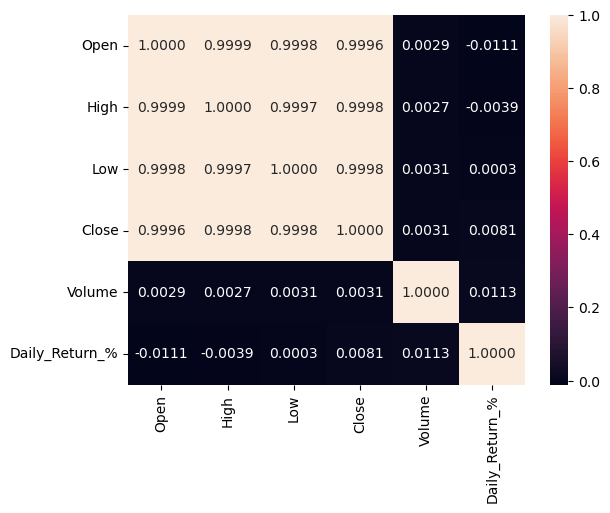

In [11]:
sns.heatmap(correlation,fmt='.4f', annot=True)

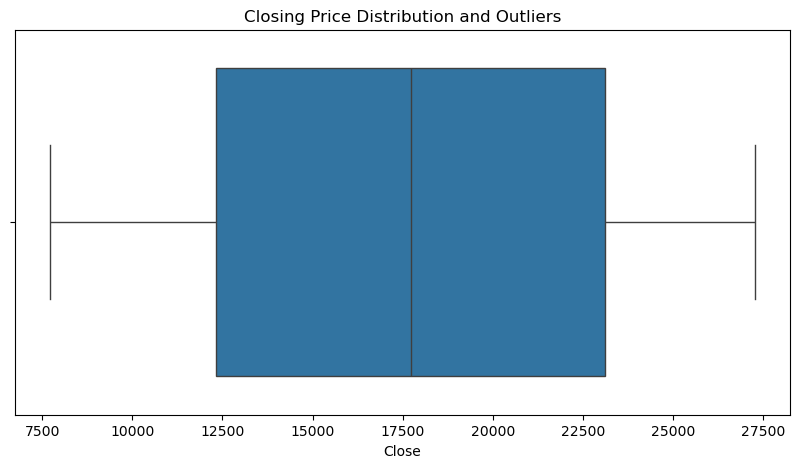

In [12]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="Close")
plt.title("Closing Price Distribution and Outliers")
plt.show()

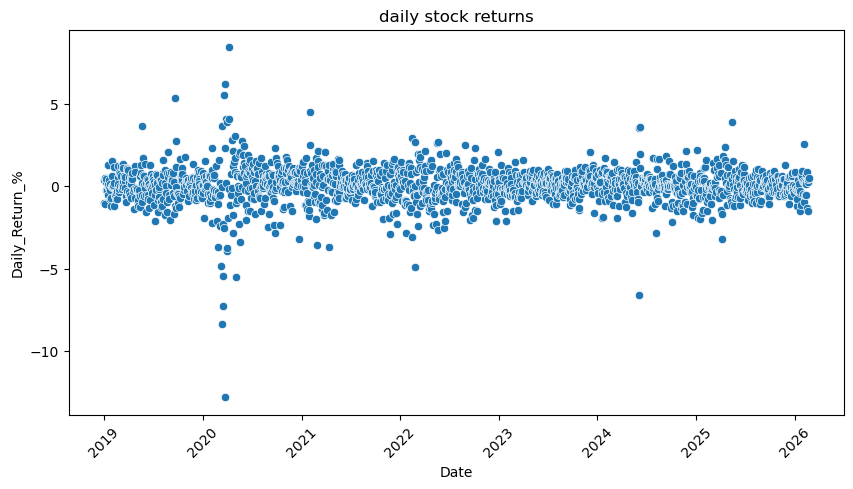

In [13]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df, y="Daily_Return_%", x="Date")
plt.xticks(rotation=45)
plt.title("daily stock returns")
plt.show() # show volatility (show outliers on perticular day when market is increase or decrease)

In [14]:
# Highest daily return
highest_return = df.loc[df["Daily_Return_%"].idxmax()]

print("Highest Daily Return:")
print("Date:", highest_return["Date"])
print("Return:", highest_return["Daily_Return_%"], "%")
# Lowest daily return
lowest_return = df.loc[df["Daily_Return_%"].idxmin()]

print("Lowest Daily Return:")
print("Date:", lowest_return["Date"])
print("Return:", lowest_return["Daily_Return_%"], "%")

Highest Daily Return:
Date: 2020-04-07 00:00:00
Return: 8.42697261721279 %
Lowest Daily Return:
Date: 2020-03-23 00:00:00
Return: -12.7987272104062 %


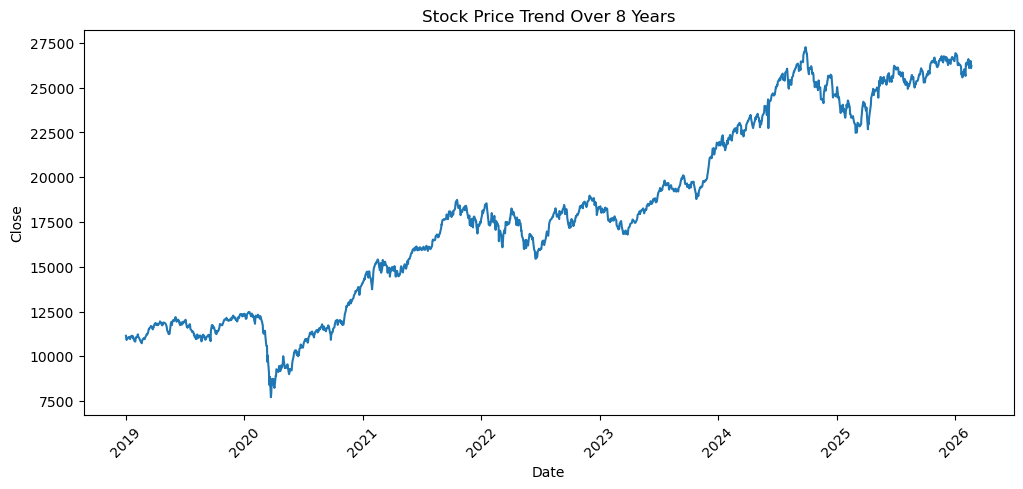

In [15]:
plt.figure(figsize=(12,5))
sns.lineplot(data=df, x="Date", y="Close")
plt.xticks(rotation=45)
plt.title("Stock Price Trend Over 8 Years")
plt.show()

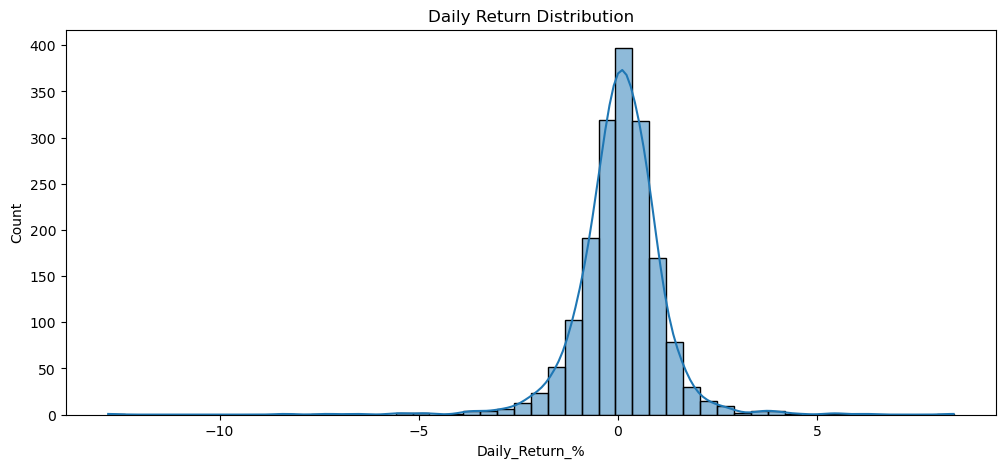

In [16]:
plt.figure(figsize=(12,5))
sns.histplot(
    data=df,
    x="Daily_Return_%",
    bins=50,
    kde=True
)

plt.title("Daily Return Distribution")
plt.show()

In [17]:
df["Target_Close"] = df["Close"].shift(-1)
df = df.dropna()


In [18]:
x=df[['High','Low','Open','Volume','Close']]
y=df['Target_Close']

In [19]:
df

,Date,Close,High,Low,Open,Volume,Daily_Return_%,Target_Close
0,2019-01-01,11148.799805,11161.000000,11051.500000,11130.549805,2616900,0.347875,11032.000000
1,2019-01-02,11032.000000,11139.450195,10977.650391,11110.150391,4795700,-1.047645,10914.799805
2,2019-01-03,10914.799805,11059.549805,10904.849609,11035.700195,4630100,-1.062366,10966.150391
3,2019-01-04,10966.150391,10981.450195,10869.450195,10940.900391,4630800,0.470468,11005.099609
4,2019-01-07,11005.099609,11070.200195,10983.549805,11044.049805,4088600,0.355177,11031.299805
...,...,...,...,...,...,...,...,...
1750,2026-02-13,26092.400391,26252.800781,26063.750000,26212.250000,6712700,-1.344713,26315.349609
1751,2026-02-16,26315.349609,26331.300781,25981.449219,26034.699219,4299800,0.854460,26375.099609
1752,2026-02-17,26375.099609,26406.150391,26214.000000,26273.099609,5399400,0.227054,26484.599609
1753,2026-02-18,26484.599609,26495.199219,26302.199219,26404.400391,4961700,0.415164,26090.699219


In [20]:
split = int(len(df) * 0.8)
# split =80 %
x_train = x.iloc[:split] #x_train 80%
x_test = x.iloc[split:]  #x_test above of 80%

y_train = y.iloc[:split] #y_train 80%
y_test = y.iloc[split:]  

In [21]:
print(x_train.shape)
print(x_test.shape)

(1404, 5)
(351, 5)


In [22]:
from sklearn.linear_model import LinearRegression
reg_model=LinearRegression()
reg_model.fit(x_train,y_train)
reg_pred = reg_model.predict(x_test)
LinearRegression()

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
prediction = pd.DataFrame({
    'actual_price': y_test,
    'predicted_price': reg_pred
})

prediction.head(10)

,actual_price,predicted_price
1404,26425.250000,26440.593899
1405,26821.000000,26458.280332
1406,27024.099609,26843.314268
1407,27027.500000,27033.039184
1408,27051.650391,27039.230999
1409,27256.250000,27063.191744
1410,27253.849609,27268.732706
1411,26890.150391,27267.576121
1412,26885.250000,26933.294907
1413,26305.250000,26902.389490


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Training data prediction
y_train_pred = reg_model.predict(x_train)

# Training data evaluation
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# Results
print("Training Data Evaluation")
print("------------------------")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("R2 Score:", round(train_r2, 4))
print("R2 Percentage:", round(train_r2 * 100, 2), "%")


Training Data Evaluation
------------------------
MAE: 114.05
RMSE: 164.5
R2 Score: 0.9985
R2 Percentage: 99.85 %


In [25]:
mae = mean_absolute_error(y_test, reg_pred)
rmse = np.sqrt(mean_squared_error(y_test, reg_pred))
r2 = r2_score(y_test, reg_pred)

# Results
print("Testing Data Evaluation")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)
print("R² Percentage:", r2 * 100, "%")

Testing Data Evaluation
MAE: 149.67390219078797
RMSE: 199.99197945823133
R² Score: 0.9647420475201324
R² Percentage: 96.47420475201324 %


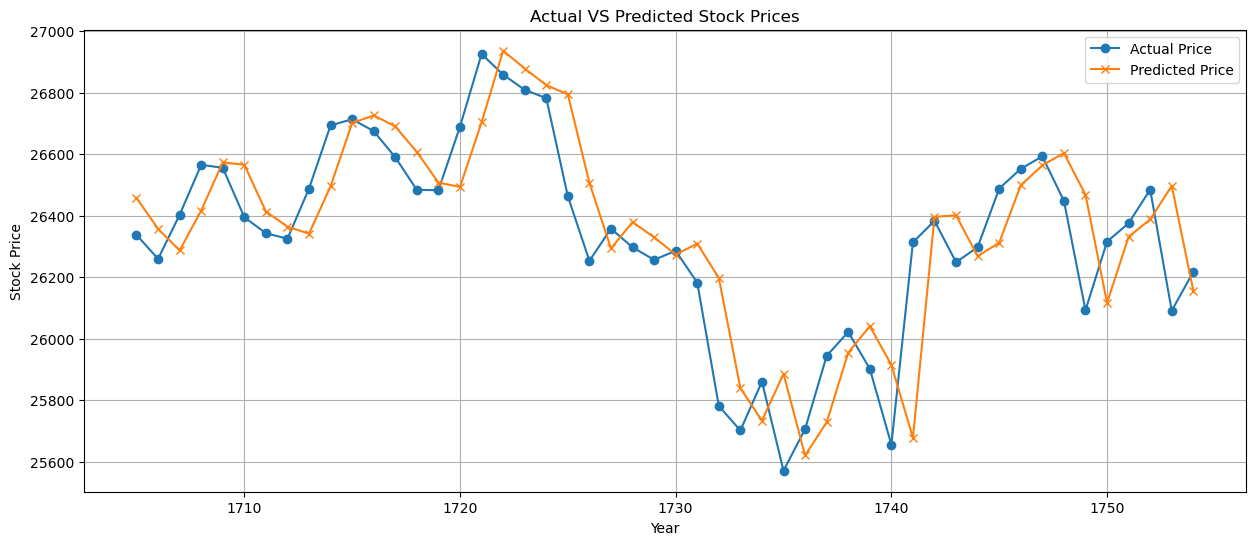

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,6))

plt.plot(prediction["actual_price"].tail(50),
         label= "Actual Price",
         marker="o")
plt.plot(prediction["predicted_price"].tail(50), 
         label="Predicted Price", 
         marker="x")

plt.title("Actual VS Predicted Stock Prices")
plt.xlabel("Year")
plt.ylabel("Stock Price")

plt.legend()
plt.grid(0.5)
plt.show()


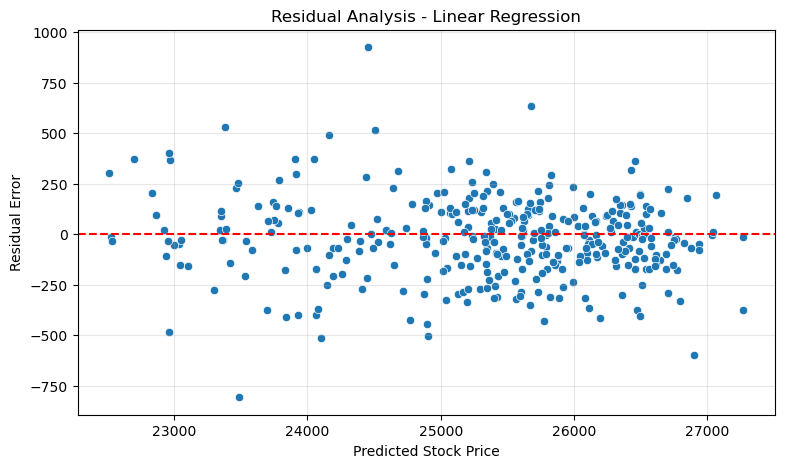

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

# Residuals
residuals = y_test - reg_pred

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=reg_pred,
    y=residuals
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Stock Price")
plt.ylabel("Residual Error")
plt.title("Residual Analysis - Linear Regression")
plt.grid(True, alpha=0.3)
plt.show()
